# Single-model pipeline — stage-by-stage experiments

Phase 2 runs **one** background model whose foreground mask feeds the structural
filter and the dwell-time FSM (see `readme.md`). This notebook:

1. exposes every tunable **parameter** of the pipeline with a short description,
2. runs the pipeline over both study cases (**busStation**, **canoe**) and shows
   a per-case **grid** of the four pipeline stages —
   *input → HSV shadow filter → foreground (bg-model output) → after morphology →
   object contour + bounding box*,
3. **evaluates** the result against the CDNET groundtruth for both cases,
4. **flags per-frame Sign of Life** (area-based) with a region-area table per case,
5. **dumps** the masks + `sign_of_life.txt` per case to `RESULTS_DIR`
   (same layout as the C++ tool's `results_cpp/`).

The parameters cell is the single place to change the experiment; every later
cell reads from it, so edit-and-rerun sweeps only the values you care about.
The first two knobs there pick **which dataset to read** (`DATASET_ROOT` — one
pre-built tree per resolution, QVGA or QQVGA) and **where to write the dump**
(`RESULTS_DIR`).

In [1]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from scr import PipelineConfig, SignOfLifePipeline
from scr.config import (
    BGSConfig,
    BlobConfig,
    DenoiseMethod,
    FeatureConfig,
    FeatureKind,
    Implementation,
    PreprocessConfig,
    ShadowConfig,
    SignOfLifeConfig,
)
from scr.features import ShadowSuppressor
from scr.native_ops import bgr_to_hsv, hsv_to_bgr
from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks
from IPython.display import Markdown, display

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

## 1. Parameters

Everything below is an experiment knob. Grouped by pipeline layer; the defaults
reproduce the Phase-2 recommendation (native `running_gaussian`, α = 0.1) on the
**QQVGA** (160×120) tree — the Alif target resolution.

`DATASET_ROOT` selects the input tree and `RESULTS_DIR` the dump folder; they
are the two knobs to change when re-running the same experiment at another
resolution.

In [2]:
# ---- Dataset -------------------------------------------------------------
# One pre-built 0.1-fps tree per capture resolution (built by
# downsample_dataset.py); pick the one the experiment should run at:
#   data_0_1fps        native CDNET resolution (mixed, 320x240 .. 640x350)
#   data_0_1fps_qvga   320x240  (QVGA)
#   data_0_1fps_qqvga  160x120  (QQVGA -- the Alif target)
# Keep RESIZE = None so the pipeline runs at the tree's own resolution; set an
# explicit (width, height) only to rescale on the fly (e.g. QVGA from `data`).
DATASET_ROOT = Path("data_0_1fps_qvga")
CASES = ["busStation", "canoe"]

# ---- Output --------------------------------------------------------------
# Folder for the dumped per-frame masks + sign_of_life.txt report (section 6).
# Uses the same layout/format as the C++ tool's results_cpp for a direct
# comparison. Give each resolution its own folder so runs do not overwrite each
# other (results_notebook = QVGA, results_notebook_qqvga = QQVGA).
RESULTS_DIR = "results_notebook_qvga_shadows_on"

# ---- Layer 0: preprocessing ----------------------------------------------
RESIZE = None                     # (width, height) to rescale to; None = as read
DENOISE = DenoiseMethod.GAUSSIAN  # sensor-noise filter before modelling

# ---- Implementation ------------------------------------------------------
# NATIVE = pure-NumPy path with no OpenCV dependency for the model (scr/models),
# the HSV shadow veto and the morphology (scr/native_ops); LIB = OpenCV/pybgs.
# The native ops are bit-exact with OpenCV, so switching this does not change
# the masks or scores -- only the dependency (the C / Alif port targets NATIVE).
IMPLEMENTATION = Implementation.NATIVE

# ---- Layer 2: feature transform + HSV shadow veto ------------------------
FEATURE = FeatureKind.GRAY        # differencing metric: gray / lbp / chromaticity
SHADOW = ShadowConfig(
    enabled=True,
    value_ratio_min=0.40,         # a cast shadow keeps 40-95% of the background
    value_ratio_max=0.95,         #   brightness (V_frame / V_background) ...
    saturation_delta_max=40.0,    #   ... with roughly unchanged saturation ...
    hue_delta_max=12.0,           #   ... and hue (OpenCV 0-179 scale)
    implementation=IMPLEMENTATION,  # native = scr.native_ops.bgr_to_hsv
)

# ---- Layer 1: background model -------------------------------------------
BACKEND = "running_gaussian"            # Phase-2 pick: best F1-per-resource
ALPHA = 0.10                            # learning rate; ~1/ALPHA frames to absorb
THRESHOLD = 25.0                        # native-backend foreground threshold

# ---- Layer 3: morphology + area gate -------------------------------------
# NOTE: the pixel-count knobs below (min_area, SOL_AREA_THRESHOLD) are tied to
# the working resolution -- an object covers 4x fewer pixels at QQVGA than at
# QVGA -- so they need rescaling when DATASET_ROOT changes resolution.
BLOB = BlobConfig(
    min_area=150,                 # drop blobs smaller than this many pixels
    open_kernel=3,                # opening removes speckle ...
    close_kernel=7,               # ... closing bridges small gaps
    implementation=IMPLEMENTATION,  # native = scr.native_ops morphology
)

# ---- Layer 3: per-frame Sign-of-Life trigger -----------------------------
# The frame is flagged Sign-of-Life when ANY region (blob) surviving the
# structural filter has an area >= this many pixels. Independent of the dwell
# FSM. Tune against the region areas shown in the per-case tables (section 5).
SOL_AREA_THRESHOLD = 500

# ---- Visualisation / scoring ---------------------------------------------
GRID_MAX_FRAMES = 6               # rows per case grid (evenly sampled)
FG_THRESHOLD = 127                # prediction > this counts as foreground


def build_config() -> PipelineConfig:
    """Assemble a PipelineConfig from the parameters above."""
    return PipelineConfig(
        preprocess=PreprocessConfig(resize=RESIZE, denoise=DENOISE),
        feature=FeatureConfig(kind=FEATURE),
        shadow=SHADOW,
        bgs=BGSConfig(
            backend=BACKEND,
            learning_rate=ALPHA,
            threshold=THRESHOLD,
            implementation=IMPLEMENTATION,
        ),
        blob=BLOB,
        sign_of_life=SignOfLifeConfig(area_threshold=SOL_AREA_THRESHOLD),
    )


print("Model :", IMPLEMENTATION.value, BACKEND, f"(alpha={ALPHA})")
print("Input :", DATASET_ROOT, "->", CASES, f"(resize={RESIZE or 'as read'})")
print("Output:", RESULTS_DIR)

Model : native running_gaussian (alpha=0.1)
Input : data_0_1fps_qvga -> ['busStation', 'canoe'] (resize=as read)
Output: results_notebook_qvga_shadows_on


## 2. Run the pipeline

`run_case` feeds a whole sequence through a fresh `SignOfLifePipeline` and keeps,
per frame, the four stage images plus the frame number for scoring.

The **HSV shadow filter** panel is reconstructed exactly: the veto uses the
background estimate as of the *previous* frame, so we snapshot
`pipeline.model.background_bgr` **before** each `process()` call and feed it to a
`ShadowSuppressor` built from the same `SHADOW` config. With `IMPLEMENTATION =
NATIVE`, that veto (and the panel's red tint below) runs the pure-NumPy
`bgr_to_hsv` / `hsv_to_bgr` from `scr.native_ops`, and the morphology runs the
native `morphology_ex` -- no OpenCV in the HSV or morphology stages.

In [3]:
def discover_frames(case: str) -> list[Path]:
    directory = DATASET_ROOT / case / "input"
    return sorted(
        p for p in directory.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES
    )


def run_case(case: str) -> list[dict]:
    """Run the pipeline over one case, returning per-frame stage images."""
    pipeline = SignOfLifePipeline.from_config(build_config())
    suppressor = ShadowSuppressor(SHADOW)  # same config -> reproduces the veto
    records: list[dict] = []
    for path in discover_frames(case):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            continue
        background = pipeline.model.background_bgr  # state after previous frame
        result = pipeline.process(image)
        records.append(
            {
                "number": frame_number(path),
                "name": path.name,  # source frame filename (for the dumped report)
                "input": result.frame.bgr,
                "shadow": suppressor.shadow_mask(result.frame, background),
                "foreground": result.foreground,
                "filtered": result.filtered_mask,
                "blobs": result.blobs,  # each carries .bbox, .area, native .contour
                "sign_of_life": result.sign_of_life,  # per-frame area-based flag
            }
        )
    return records


results = {case: run_case(case) for case in CASES}
for case in CASES:
    records = results[case]
    # Report the resolution the pipeline actually worked at -- it comes from the
    # dataset when RESIZE is None, so this is the check that DATASET_ROOT and
    # RESIZE agree.
    height, width = records[0]["input"].shape[:2]
    print(f"{case}: {len(records)} frames processed at {width}x{height}")

busStation: 6 frames processed at 320x240
canoe: 5 frames processed at 320x240


## 3. Stage grid per case

Each row is one frame; the columns follow the pipeline left to right:

| Column | Content |
| --- | --- |
| **Input** | Preprocessed (denoised) frame, at the `DATASET_ROOT` resolution |
| **HSV shadow filter** | Detected cast-shadow pixels tinted red, via the native BGR→HSV→BGR round-trip |
| **Foreground (bg model)** | The model's foreground mask — the veto has already removed the red pixels |
| **After morphology** | Foreground after opening/closing and the area gate — the pipeline's final mask |
| **Object: contour + bbox** | Input with each detected blob's native contour (red) and bounding box (green) drawn on it |

The last panel uses the **native** connected-components labelling and
Moore-neighbour contour tracing (`scr.native_ops`): each surviving blob carries
its outer contour and bounding box, drawn as matplotlib overlays on the input
(the image itself is untouched).

In [4]:
COLUMN_TITLES = [
    "Input",
    "HSV shadow filter",
    "Foreground (bg model)",
    "After morphology",
    "Object: contour + bbox",
]


def shadow_overlay(bgr: np.ndarray, shadow: np.ndarray) -> np.ndarray:
    """Tint shadow pixels red *in HSV space* and convert back.

    This exercises the native round-trip end to end: BGR -> HSV with
    ``bgr_to_hsv``, recolour the detected-shadow pixels (hue = red, full
    saturation, value kept so the shadow's own shading stays visible), then
    HSV -> BGR with ``hsv_to_bgr``. The final BGR -> RGB flip for matplotlib is
    a plain NumPy channel reversal, so the whole panel is OpenCV-free.
    """
    hsv = bgr_to_hsv(bgr).copy()          # native BGR -> HSV
    mask = shadow > 0
    hsv[mask, 0] = 0                       # hue -> red
    hsv[mask, 1] = 255                     # full saturation
    tinted = hsv_to_bgr(hsv)              # native HSV -> BGR
    return tinted[:, :, ::-1]            # BGR -> RGB (NumPy)


def sample_rows(records: list[dict], k: int) -> list[dict]:
    """Evenly sample up to k frames across the sequence."""
    if len(records) <= k:
        return records
    idx = np.linspace(0, len(records) - 1, k).round().astype(int)
    return [records[i] for i in idx]


def draw_detections(ax, record: dict) -> None:
    """Draw each blob's native contour (red) and bbox (green) on the input."""
    ax.imshow(record["input"][:, :, ::-1])
    for blob in record["blobs"]:
        x, y, width, height = blob.bbox
        ax.add_patch(
            Rectangle((x, y), width, height, fill=False, edgecolor="lime", linewidth=1.4)
        )
        contour = blob.contour
        if contour is not None and len(contour) > 1:
            closed = np.vstack([contour, contour[:1]])  # close the loop
            ax.plot(closed[:, 0], closed[:, 1], color="red", linewidth=1.0)


def show_grid(case: str, records: list[dict]) -> None:
    rows = sample_rows(records, GRID_MAX_FRAMES)
    columns = len(COLUMN_TITLES)
    fig, axes = plt.subplots(len(rows), columns, figsize=(16, 3.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, record in enumerate(rows):
        panels = [
            record["input"][:, :, ::-1],  # BGR -> RGB (NumPy)
            shadow_overlay(record["input"], record["shadow"]),
            record["foreground"],
            record["filtered"],
        ]
        for c in range(columns):
            ax = axes[r][c]
            if c < len(panels):
                image = panels[c]
                if image.ndim == 3:
                    ax.imshow(image)
                else:
                    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            else:
                draw_detections(ax, record)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(COLUMN_TITLES[c], fontsize=11)
            if c == 0:
                ax.set_ylabel(f"frame #{record['number']}", fontsize=10)
    fig.suptitle(f"{case} — pipeline stages ({BACKEND}, alpha={ALPHA})", fontsize=13)
    fig.tight_layout()
    plt.show()

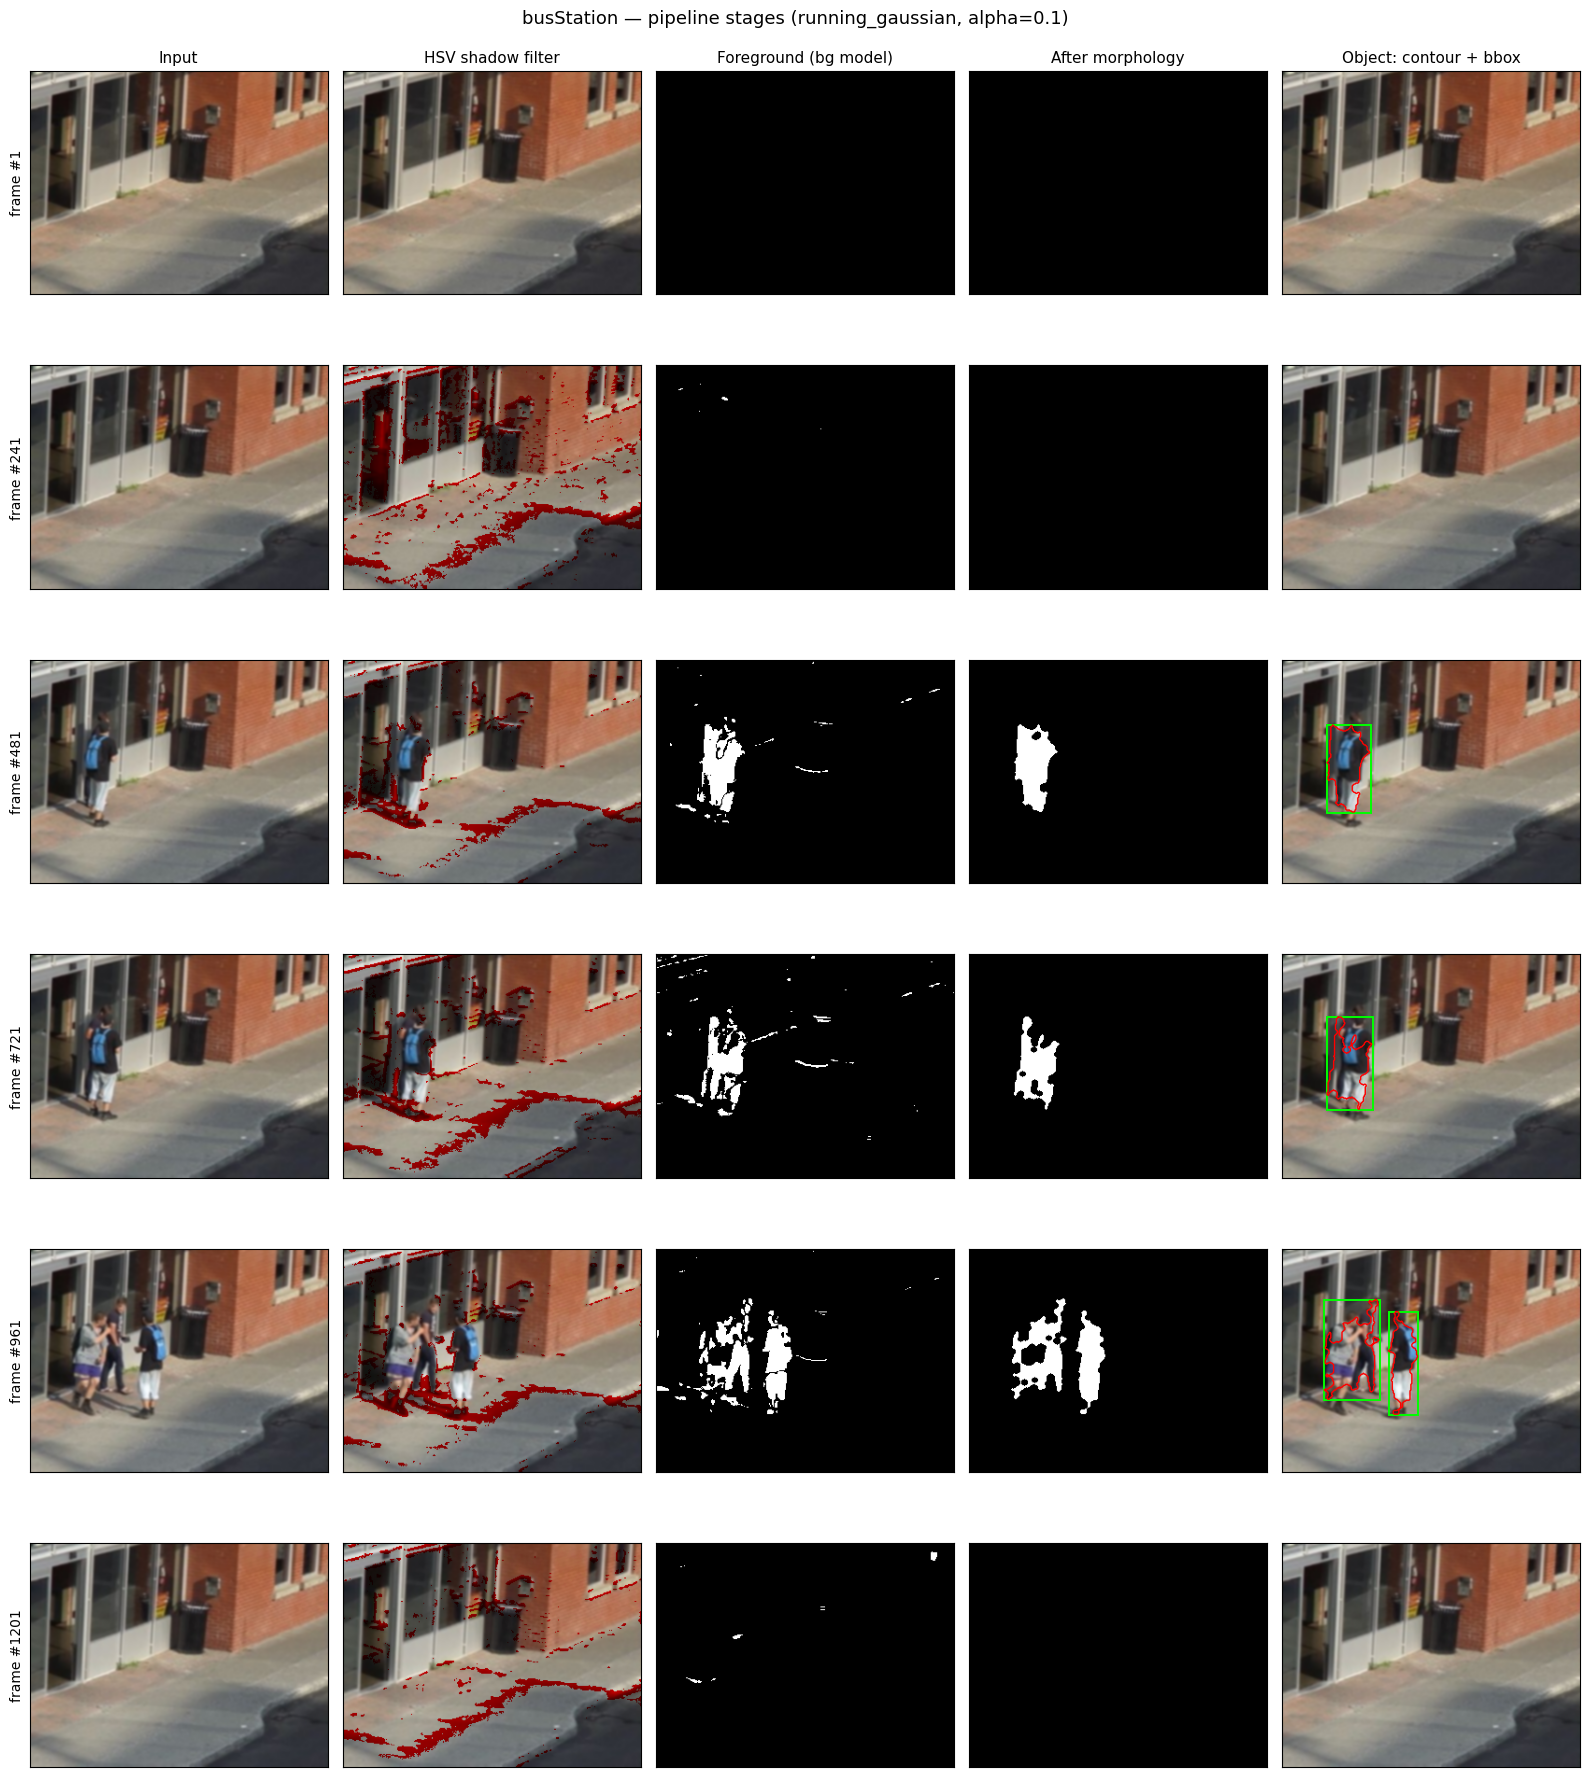

In [5]:
show_grid('busStation', results['busStation'])

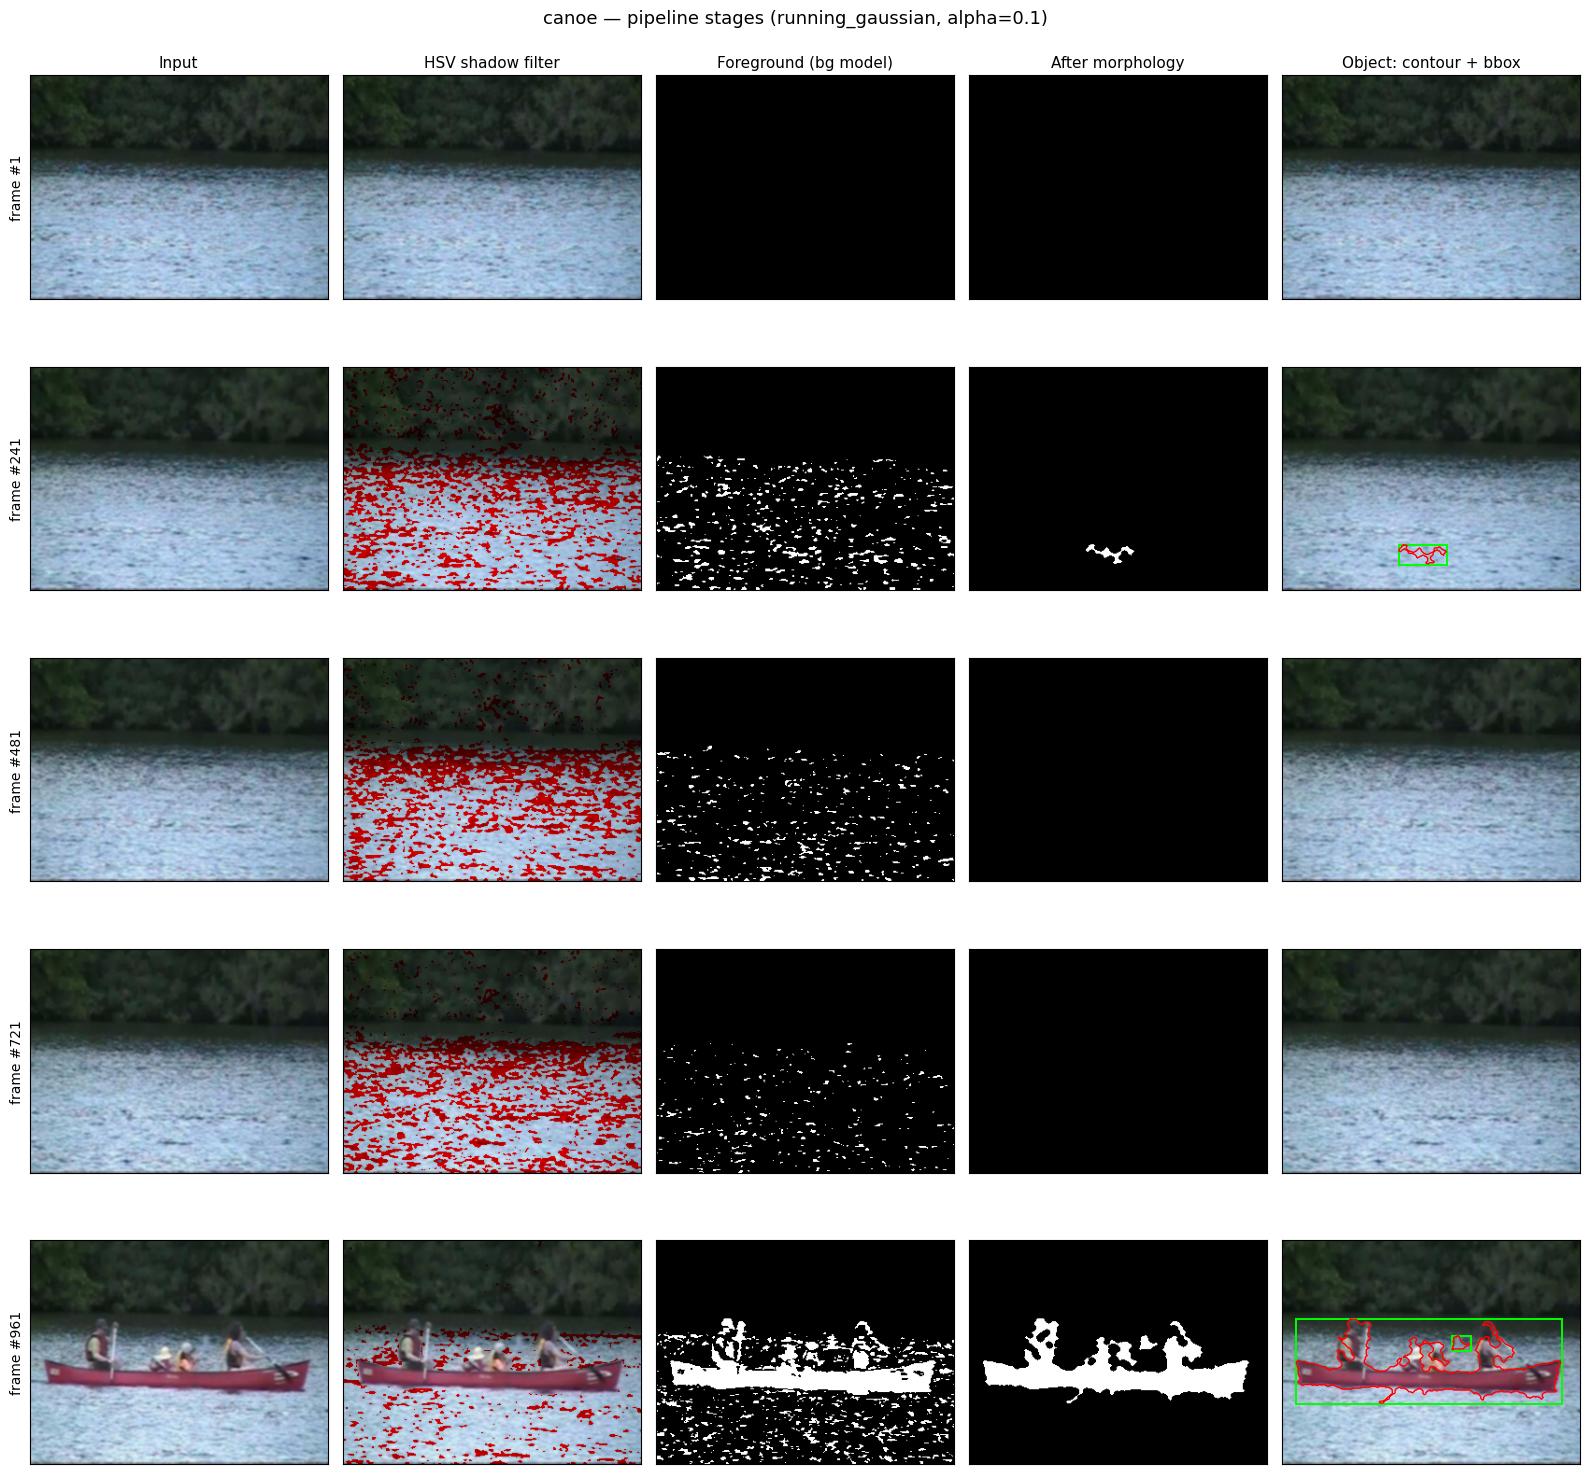

In [6]:
show_grid('canoe', results['canoe'])

## 4. Evaluation

Both masks are scored against the CDNET groundtruth: the raw **foreground**
(bg-model output, comparable to the Phase-1 model sweep) and the **filtered**
mask (the pipeline's final product, after morphology). Following the CDNET
protocol, only pixels whose groundtruth is exactly `0` or `255` are counted;
shadow (50), unknown (170) and outside-ROI (85) pixels are ignored, and frames
with no such pixels are skipped. Predictions are resized to the groundtruth
resolution inside `accumulate_counts`.

In [7]:
def evaluate_case(case: str, records: list[dict], mask_key: str) -> dict:
    groundtruth = index_masks(DATASET_ROOT / case / "groundtruth")
    tp = fp = fn = tn = frames = 0
    for record in records:
        number = record["number"]
        if number not in groundtruth:
            continue
        gt = cv2.imread(str(groundtruth[number]), cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(gt, record[mask_key], FG_THRESHOLD)
        if sum(counts) == 0:  # groundtruth is all void for this frame
            continue
        tp += counts[0]
        fp += counts[1]
        fn += counts[2]
        tn += counts[3]
        frames += 1
    result = EvaluationResult.from_counts(tp, fp, fn, tn, frames)
    return {
        "case": case,
        "mask": mask_key,
        "eval frames": result.frames,
        "precision": result.precision,
        "recall": result.recall,
        "F-measure": result.f_measure,
        "IoU": result.iou,
    }


rows = [
    evaluate_case(case, results[case], mask_key)
    for case in CASES
    for mask_key in ("foreground", "filtered")
]
scores = pd.DataFrame(rows)
scores.style.format(
    {"precision": "{:.3f}", "recall": "{:.3f}", "F-measure": "{:.3f}", "IoU": "{:.3f}"}
).hide(axis="index").background_gradient(subset=["F-measure"], cmap="RdYlGn", vmin=0, vmax=1)

case,mask,eval frames,precision,recall,F-measure,IoU
busStation,foreground,4,0.874,0.619,0.725,0.569
busStation,filtered,4,0.994,0.672,0.802,0.669
canoe,foreground,1,0.609,0.859,0.713,0.553
canoe,filtered,1,0.917,0.930,0.923,0.857


## 5. Per-frame Sign of Life

The pipeline sets `result.sign_of_life = True` for a frame when **any** region
(blob) surviving the structural filter has an area `>= SOL_AREA_THRESHOLD` px.
This is the simple per-frame presence signal (independent of the dwell-time
FSM). One table per case lists, per frame, the flag and every region's area so
the threshold can be tuned by eye.

In [8]:
def sol_table(records: list[dict]) -> pd.DataFrame:
    """Per-frame Sign-of-Life flag and the areas of every detected region."""
    rows = []
    for record in records:
        areas = sorted((int(b.area) for b in record["blobs"]), reverse=True)
        rows.append(
            {
                "frame": record["number"],
                "Sign of Life": bool(record["sign_of_life"]),
                "regions": len(areas),
                "region areas (px)": areas,
            }
        )
    return pd.DataFrame(rows)


def _flag_colour(flag: bool) -> str:
    return "background-color: #b7e4a0" if flag else "background-color: #f4b9b9"


for case in CASES:
    display(Markdown(f"#### {case} — threshold = {SOL_AREA_THRESHOLD} px"))
    table = sol_table(results[case])
    display(
        table.style.hide(axis="index").map(_flag_colour, subset=["Sign of Life"])
    )

#### busStation — threshold = 500 px

frame,Sign of Life,regions,region areas (px)
1,False,0,[]
241,False,0,[]
481,True,1,[2596]
721,True,1,[2252]
961,True,2,"[2622, 1909]"
1201,False,0,[]


#### canoe — threshold = 500 px

frame,Sign of Life,regions,region areas (px)
1,False,0,[]
241,False,1,[294]
481,False,0,[]
721,False,0,[]
961,True,2,"[9658, 165]"


## 6. Dump results to files

Write the same artefacts the C++ tool produces, per case, into
`<RESULTS_DIR>/<case>/`:

- `<frame>_raw.png` — foreground mask (bg-model output after the shadow veto),
- `<frame>_morph.png` — mask after morphology + area gate,
- `sign_of_life.txt` — per-frame flag, object count and object sizes
  (`area@x,y,w,h`).

The layout and the report format match `results_cpp/` (produced by
`run_cpp_pipeline.py`), so the notebook and C++ outputs can be diffed directly.
The masks are written at the working resolution, so keep one `RESULTS_DIR` per
`DATASET_ROOT` rather than mixing resolutions in one folder.

In [9]:
from pathlib import Path


def dump_case(case: str, records: list[dict]) -> Path:
    """Write per-frame masks and a sign_of_life.txt report for one case."""
    out_dir = Path(RESULTS_DIR) / case
    out_dir.mkdir(parents=True, exist_ok=True)

    lines = [
        "# Sign-of-Life report",
        f"# min_area={BLOB.min_area} area_threshold={SOL_AREA_THRESHOLD}",
        "# columns: frame  sign_of_life  num_objects  objects[area@x,y,w,h;...]",
    ]
    sol_count = 0
    for record in records:
        stem = Path(record["name"]).stem
        cv2.imwrite(str(out_dir / f"{stem}_raw.png"), record["foreground"])
        cv2.imwrite(str(out_dir / f"{stem}_morph.png"), record["filtered"])

        objects = ";".join(
            f"{b.area}@{b.bbox[0]},{b.bbox[1]},{b.bbox[2]},{b.bbox[3]}"
            for b in record["blobs"]
        )
        flag = 1 if record["sign_of_life"] else 0
        sol_count += flag
        lines.append(f"{record['name']}  {flag}  {len(record['blobs'])}  {objects}")

    lines.append(f"# summary: {len(records)} frames, {sol_count} sign-of-life")
    (out_dir / "sign_of_life.txt").write_text("\n".join(lines) + "\n")
    return out_dir


for case in CASES:
    out_dir = dump_case(case, results[case])
    print(f"{case}: dumped {len(results[case])} frames -> {out_dir}")

busStation: dumped 6 frames -> results_notebook_qvga_shadows_on/busStation
canoe: dumped 5 frames -> results_notebook_qvga_shadows_on/canoe


### Notes

- **Thin groundtruth at 0.1 fps.** The decimated set exposes only a handful of
  labelled frames (busStation ≈ 3–4, canoe = 1), so the scores are indicative,
  not statistically tight. Point `DATASET_ROOT` at `data` for a full-sequence
  F-measure over the temporal ROI.
- **`foreground` vs `filtered`.** Morphology and the area gate trade recall for
  precision; on dynamic-background clips (canoe water) they legitimately remove
  most of the mask, which can drop the filtered F-measure toward zero.
- **One knob, one trade-off.** With a single model, `ALPHA` balances crisp
  segmentation (higher α) against retaining a deposited object for the dwell FSM
  (lower α). Sweep it here and watch the grid + scores move together.